# Classificação de diabetes com XGBoost (dataset NIDDK)

<mark>Este notebook é didático e não deve ser utilizado para realizar diagnósticos</mark>

Este notebook utiliza os dados preparados por `02-prepare-niddk-diabetes.ipynb` para treinar e avaliar um único classificador binário: **XGBoost**. O fluxo é intencionalmente compacto: carregar os dados, definir `X` e `y`, separar os conjuntos, treinar o modelo e avaliar suas previsões.

## Importações e caminhos do projeto

### Bibliotecas

In [49]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")


def find_project_root() -> Path:
    """Retorna a raiz do repositório quando o notebook é executado neste projeto."""
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "ml" / "pyproject.toml").is_file() and (
            candidate / "README.md"
        ).is_file():
            return candidate
    raise FileNotFoundError("Abra este notebook dentro do repositório do projeto.")

### Variáveis

In [50]:
PROJECT_ROOT = find_project_root()

DATA_PATH = PROJECT_ROOT / "data" / "niddk-diabetes" / "diabetes.parquet"
TARGET_COLUMN = "diabetes"
IDENTIFIER_COLUMN = "id_paciente"

RANDOM_STATE = 42

## Carregar o dataset preparado

O notebook de preparação traduz as colunas de origem para português e as salva em Parquet. Antes de prosseguir, verificamos se as colunas de alvo e identificador esperadas estão presentes.

In [51]:
if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset preparado não encontrado em {DATA_PATH}. "
        "Execute primeiro 02-prepare-niddk-diabetes.ipynb."
    )

data = pd.read_parquet(DATA_PATH)
required_columns = {TARGET_COLUMN, IDENTIFIER_COLUMN}
missing_columns = required_columns.difference(data.columns)
if missing_columns:
    raise ValueError(f"O dataset não possui as colunas obrigatórias: {sorted(missing_columns)}")

print(f"Dimensões do dataset: {data.shape}")

Dimensões do dataset: (10000, 10)


In [52]:
print(f"Distribuição das classes:\n{data[TARGET_COLUMN].value_counts(normalize=True).sort_index()}")

Distribuição das classes:
diabetes
0    0.6656
1    0.3344
Name: proportion, dtype: float64


In [53]:
display(data.head())

,id_paciente,gestacoes,glicose_plasmatica,pressao_arterial_diastolica,espessura_triceps,insulina_serica,imc,indice_hereditariedade_diabetes,idade,diabetes
0,1354778,0,171,80,34,23,43.509726,1.213191,21,0
1,1147438,8,92,93,47,36,21.240576,0.158365,23,0
2,1640031,7,115,47,52,35,41.511523,0.079019,23,0
3,1883350,9,103,78,25,304,29.582192,1.282870,43,1
4,1424119,1,85,59,27,35,42.604536,0.549542,22,0


## Separar os conjuntos em variáveis de entrada `X` e alvo `y`

`diabetes` é o desfecho binário a ser previsto. `id_paciente` é removida porque identifica um registro em vez de descrever uma característica da pessoa, as demais colunas formam `X`.

In [54]:
feature_columns = [
    column for column in data.columns if column not in {TARGET_COLUMN, IDENTIFIER_COLUMN}
]

X = data[feature_columns]
y = data[TARGET_COLUMN]

print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")
print(f"Variáveis de entrada: {feature_columns}")

Dimensões de X: (10000, 8)
Dimensões de y: (10000,)
Variáveis de entrada: ['gestacoes', 'glicose_plasmatica', 'pressao_arterial_diastolica', 'espessura_triceps', 'insulina_serica', 'imc', 'indice_hereditariedade_diabetes', 'idade']


## Criar os conjuntos de treino e teste

O conjunto de teste fica reservado até a avaliação. `stratify=y` preserva a proporção das classes em ambas as divisões, e `random_state` torna o resultado reproduzível.

In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE,
)

print(f"Conjunto de treino: {X_train.shape[0]} linhas")
print(f"Conjunto de teste:  {X_test.shape[0]} linhas")
print(f"Variáveis:          {X_train.shape[1]}")

Conjunto de treino: 8000 linhas
Conjunto de teste:  2000 linhas
Variáveis:          8


## Treinar um classificador XGBoost

O XGBoost constrói um conjunto de árvores de decisão sequencialmente; cada nova árvore se concentra nos erros das árvores anteriores. Modelos baseados em árvores não exigem padronização das variáveis, portanto nenhum escalonador é usado aqui. Os parâmetros abaixo são explícitos e moderados para uma linha de base reproduzível.

In [56]:
model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

model.fit(X_train, y_train)

print("Treinamento do XGBoost concluído.")

Treinamento do XGBoost concluído.


## Avaliar no conjunto de testes

As probabilidades previstas são usadas para o ROC-AUC, enquanto as classes usam o limiar padrão de 0,5 do modelo. Precisão, revocação e F1 complementam a acurácia porque distinguem diferentes tipos de erro de classificação.

In [57]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]

metrics = pd.Series(
    {
        "Acurácia": accuracy_score(y_test, y_pred),
        "Precisão": precision_score(y_test, y_pred, zero_division=0),
        "Revocação": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, y_probability),
    }
)

In [58]:
display(metrics.to_frame("métrica").round(3))

,métrica
Acurácia,0.952
Precisão,0.929
Revocação,0.925
F1,0.927
ROC-AUC,0.990


In [59]:
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

              precision    recall  f1-score   support

           0      0.963     0.965     0.964      1331
           1      0.929     0.925     0.927       669

    accuracy                          0.952      2000
   macro avg      0.946     0.945     0.945      2000
weighted avg      0.951     0.952     0.951      2000



## Examinar erros e a importância das variáveis

A matriz de confusão compara as classes previstas com as reais. A importância das variáveis é um resumo específico do modelo sobre a frequência e a eficácia com que uma variável foi usada nas árvores aprendidas; ela não estabelece causalidade ou relevância clínica.

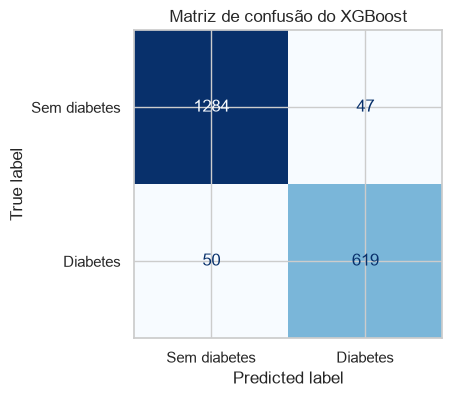

In [62]:
fig, ax = plt.subplots(figsize=(5, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Sem diabetes", "Diabetes"],
    cmap="Blues",
    colorbar=False,
    ax=ax,
)

ax.set_title("Matriz de confusão do XGBoost")
plt.show()

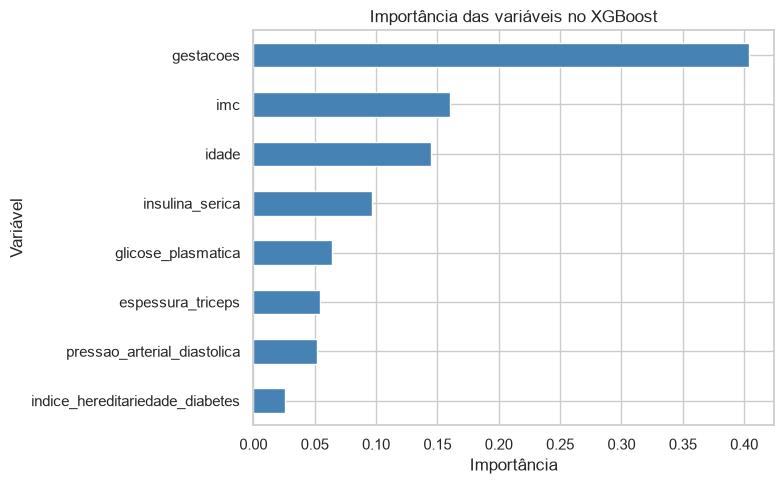

In [63]:
feature_importance = (
    pd.Series(model.feature_importances_, index=feature_columns)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(8, 5))
feature_importance.plot.barh(ax=ax, color="steelblue")

ax.set_title("Importância das variáveis no XGBoost")
ax.set_xlabel("Importância")
ax.set_ylabel("Variável")

plt.tight_layout()
plt.show()